# Nepal Flood — Media–Public Emotional Divergence
### A framework for measuring and tracking how media and public emotion diverge during a crisis

**Core contributions (the novel parts):**
1. **A media–public emotional divergence metric** — quantifies *how far apart* newspaper (media)
   and YouTube (public) emotions are, with bootstrap confidence intervals (handles the unequal corpus sizes).
2. **Temporal divergence dynamics** — tracks how that gap *opens and closes over time* after the disaster.

**Supporting rigor (validation):**
3. **Multi-model + XAI** — several emotion models (lexicon + transformer + VAD) plus SHAP/LIME on an
   XGBoost source-classifier, showing *which words* drive the divergence.

Method settings are kept **consistent with the measles study**: regex sentence-splitting,
≥5-word sentences, VADER threshold ±0.05, XGBoost + SHAP/LIME for explainability.

> **Runtime → Change runtime type → T4 GPU** before running.


## Step 0 — Setup

In [1]:
!pip install -q nrclex vaderSentiment textblob transformers torch scikit-learn xgboost shap lime scipy ruptures matplotlib seaborn nltk pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 11.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 57.0 MB/s eta 0:00:00


In [2]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, re, json, time, urllib.request
import matplotlib.pyplot as plt, seaborn as sns
sns.set(style="whitegrid")
import nltk
for pkg in ["punkt","punkt_tab","vader_lexicon","brown","wordnet",
            "averaged_perceptron_tagger","averaged_perceptron_tagger_eng","omw-1.4"]:
    try: nltk.download(pkg, quiet=True)
    except Exception as e: print("nltk", pkg, e)

import torch
DEVICE = 0 if torch.cuda.is_available() else -1
print("GPU available:", torch.cuda.is_available(), "| device:", DEVICE,
      "(0 = GPU, -1 = CPU)")

GPU available: True | device: 0 (0 = GPU, -1 = CPU)


## Step 1 — Load both corpora & split into sentences
Measles-consistent: regex sentence-split `(?<=[.!?])\s+`, keep sentences with **≥5 words**.
No keyword filter (the corpora are already Nepal-flood specific, and comments rarely contain the word "flood").

In [3]:
# ---- CONFIG ----
NEWS_CSV="nepal_flood_news_v2.csv"; NEWS_TEXT="full_text"; NEWS_DATE="date"
YT_CSV="nepal_youtube_comments_clean.csv"; YT_TEXT="comment_text"; YT_DATE="published"
SAMPLE_PER_SOURCE=None   # set e.g. 4000 for a quick first run; None = all
# ----------------

def clean(t):
    t=re.sub(r"http\S+"," ",str(t)); t=re.sub(r"<[^>]+>"," ",t)
    return re.sub(r"\s+"," ",t).strip()

def to_sentences(df, tcol, dcol, source):
    rows=[]
    for _,r in df.iterrows():
        for s in re.split(r"(?<=[.!?])\s+", clean(r[tcol])):
            s=s.strip()
            if len(s.split())>=5:               # measles-consistent: >=5 words
                rows.append({"source":source,"date":r.get(dcol),"text":s})
    return pd.DataFrame(rows)

news=pd.read_csv(NEWS_CSV); yt=pd.read_csv(YT_CSV)
ns=to_sentences(news,NEWS_TEXT,NEWS_DATE,"newspaper")
ys=to_sentences(yt,YT_TEXT,YT_DATE,"youtube")
if SAMPLE_PER_SOURCE:
    ns=ns.sample(min(SAMPLE_PER_SOURCE,len(ns)),random_state=0)
    ys=ys.sample(min(SAMPLE_PER_SOURCE,len(ys)),random_state=0)
sents=pd.concat([ns,ys],ignore_index=True)
sents["date"]=pd.to_datetime(sents["date"],errors="coerce",utc=True)
print(sents["source"].value_counts())
sents.head()

source
newspaper    19239
youtube       6407
Name: count, dtype: int64


,source,date,text
0,newspaper,2026-08-30 08:00:00+00:00,Nepal’s National Disaster Risk Reduction and M...
1,newspaper,2026-08-30 08:00:00+00:00,Searches are continuing for thousands missing ...
2,newspaper,2026-08-30 08:00:00+00:00,The latest figures from Chinese state media re...
3,newspaper,2026-08-30 08:00:00+00:00,Nepalese authorities said among those unaccoun...
4,newspaper,2026-08-30 08:00:00+00:00,It is unclear how many are included in the Nep...


## Step 2 — Multi-model emotion & sentiment (supporting rigor)
NRCLex (8 emotions), VADER, TextBlob, RoBERTa sentiment, GoEmotions (28 emotions) — applied identically to both sources.

In [4]:
# 2a. Lexicon models
from nrclex import NRCLex
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob
vader=SentimentIntensityAnalyzer()
EMOS=["anger","fear","joy","sadness","trust","disgust","surprise","anticipation"]

def nrc(t):
    try:
        obj=NRCLex(str(t)); raw=obj.raw_emotion_scores
        tot=sum(raw.values()) or 1
        return {e: raw.get(e,0)/tot for e in EMOS}
    except Exception:
        return {e:0.0 for e in EMOS}

def vlab(t):
    c=vader.polarity_scores(str(t))["compound"]
    return "positive" if c>=0.05 else "negative" if c<=-0.05 else "neutral"
def tlab(t):
    p=TextBlob(str(t)).sentiment.polarity
    return "positive" if p>0.05 else "negative" if p<-0.05 else "neutral"

n=sents["text"].apply(nrc).apply(pd.Series); n.columns=["nrc_"+c for c in n.columns]
sents=pd.concat([sents,n],axis=1)
sents["vader"]=sents["text"].apply(vlab)
sents["textblob"]=sents["text"].apply(tlab)
# sanity check NRCLex is not all-zero:
print("NRCLex example:", nrc("I am terrified and heartbroken by this deadly flood disaster"))
print("Lexicon models done.")

NRCLex example: {'anger': 0.0, 'fear': 0.0, 'joy': 0.0, 'sadness': 0.0, 'trust': 0.0, 'disgust': 0.0, 'surprise': 0.0, 'anticipation': 0.0}
Lexicon models done.


In [5]:
# 2b. Transformers: RoBERTa sentiment + GoEmotions (max_length=128 avoids CUDA asserts)
from transformers import pipeline
texts=sents["text"].astype(str).tolist()

roberta=pipeline("sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    device=DEVICE, truncation=True, max_length=128)
sents["roberta_sent"]=[x["label"].lower() for x in roberta(texts,batch_size=16,truncation=True,max_length=128)]

goemo=pipeline("text-classification",
    model="SamLowe/roberta-base-go_emotions",
    device=DEVICE, truncation=True, max_length=128, top_k=1)
ge=goemo(texts,batch_size=16,truncation=True,max_length=128)
sents["goemotion"]=[x[0]["label"] if isinstance(x,list) else x["label"] for x in ge]
print("Transformer models done. Rows:",len(sents))
sents[["source","text","roberta_sent","goemotion"]].head()

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

... (11 outputs left out)

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

Transformer models done. Rows: 25646


,source,text,roberta_sent,goemotion
0,newspaper,Nepal’s National Disaster Risk Reduction and M...,negative,neutral
1,newspaper,Searches are continuing for thousands missing ...,negative,sadness
2,newspaper,The latest figures from Chinese state media re...,negative,sadness
3,newspaper,Nepalese authorities said among those unaccoun...,neutral,neutral
4,newspaper,It is unclear how many are included in the Nep...,neutral,confusion


## Step 3 — VAD (Valence–Arousal–Dominance) — optional dimensional layer
Continuous emotional dimensions, used as an extra pillar of the divergence metric. If the lexicon
can't be downloaded, the notebook continues without it (the core results don't depend on VAD).

In [6]:
# VAD lexicon — package দিয়ে (link এর ঝামেলা ছাড়া)
!pip install -q nrc-vad 2>/dev/null

vad_lex = None

# উপায় ১: nrc-vad package
try:
    from nrc_vad import NRCVADLexicon
    lex = NRCVADLexicon()
    # package টা কাজ করছে কিনা test
    print("nrc-vad package পাওয়া গেছে")
except Exception as e:
    print("package নেই:", e)

# উপায় ২: kaggle/HF এ থাকা copy (raw text) — কয়েকটা নির্ভরযোগ্য mirror
import urllib.request
URLS = [
    "https://huggingface.co/datasets/Blablablab/SOCKET/resolve/main/NRC-VAD-Lexicon.txt",
    "https://raw.githubusercontent.com/aesuli/SentiWordNet/master/NRC-VAD-Lexicon.txt",
    "https://raw.githubusercontent.com/marcoguerini/CROWD/master/resources/NRC-VAD-Lexicon.txt",
]
if vad_lex is None:
    for u in URLS:
        try:
            raw = urllib.request.urlopen(u, timeout=30).read().decode("utf-8","ignore")
            d = {}
            for line in raw.splitlines():
                p = line.split("\t")
                if len(p) >= 4:
                    try: d[p[0].lower()] = (float(p[1]), float(p[2]), float(p[3]))
                    except: pass
            if len(d) > 1000:
                vad_lex = d; print("VAD loaded:", len(d), "words"); break
        except Exception as e:
            print("  miss:", str(e)[:50])

if vad_lex is None:
    print("\n[!] এখনো পাওয়া গেল না — VAD বাদ দিয়েই এগোও, সমস্যা নেই।")

package নেই: No module named 'nrc_vad'
  miss: HTTP Error 404: Not Found
  miss: HTTP Error 404: Not Found
  miss: HTTP Error 404: Not Found

[!] এখনো পাওয়া গেল না — VAD বাদ দিয়েই এগোও, সমস্যা নেই।


In [ ]:
# Try several sources for the NRC-VAD lexicon; else allow manual upload of NRC-VAD-Lexicon.txt
VAD_URLS=[
 "https://raw.githubusercontent.com/bagustris/nrc_vad/main/NRC-VAD-Lexicon.txt",
 "https://raw.githubusercontent.com/dwzhou/SentiLexicon/master/NRC-VAD-Lexicon.txt",
 "https://raw.githubusercontent.com/mhagiwara/nrc-vad/master/NRC-VAD-Lexicon.txt",
]
def parse_vad(raw):
    d={}
    for line in raw.splitlines():
        p=line.split("\t")
        if len(p)>=4:
            try: d[p[0].lower()]=(float(p[1]),float(p[2]),float(p[3]))
            except: pass
    return d
vad_lex=None
for u in VAD_URLS:
    try:
        raw=urllib.request.urlopen(u,timeout=30).read().decode("utf-8","ignore")
        d=parse_vad(raw)
        if len(d)>1000: vad_lex=d; print("NRC-VAD loaded:",len(d),"words from",u.split('/')[-3]); break
    except Exception as e: print("  miss:",e)
if vad_lex is None:
    import os
    if os.path.exists("NRC-VAD-Lexicon.txt"):
        vad_lex=parse_vad(open("NRC-VAD-Lexicon.txt",encoding="utf-8",errors="ignore").read())
        print("Loaded from uploaded file:",len(vad_lex),"words")
    else:
        print("[!] VAD lexicon unavailable — continuing WITHOUT VAD (core results unaffected).")
        print("    Optional: download NRC-VAD-Lexicon.txt (saifmohammad.com) and upload to Colab.")

  miss: HTTP Error 404: Not Found
  miss: HTTP Error 404: Not Found
  miss: HTTP Error 404: Not Found
[!] VAD lexicon unavailable — continuing WITHOUT VAD (core results unaffected).
    Optional: download NRC-VAD-Lexicon.txt (saifmohammad.com) and upload to Colab.


In [ ]:
if vad_lex:
    def vad(t):
        w=re.findall(r"[a-z]+",str(t).lower())
        v=[vad_lex[x] for x in w if x in vad_lex]
        return tuple(np.mean(v,axis=0)) if v else (np.nan,np.nan,np.nan)
    vv=sents["text"].apply(vad).apply(pd.Series); vv.columns=["valence","arousal","dominance"]
    sents=pd.concat([sents,vv],axis=1)
    print(sents.groupby("source")[["valence","arousal","dominance"]].mean().round(3))
else:
    print("VAD skipped.")

VAD skipped.


## Step 4 — CORE CONTRIBUTION 1: Media–Public Divergence Metric

We represent each source as an **emotion probability distribution** (over GoEmotions labels) and
measure the distance between media and public with **Jensen–Shannon divergence (JSD)**
(0 = identical, 1 = maximally different). Because the corpora are unequal in size, we report a
**bootstrap 95% confidence interval** and a **permutation p-value** — this is the methodological core.

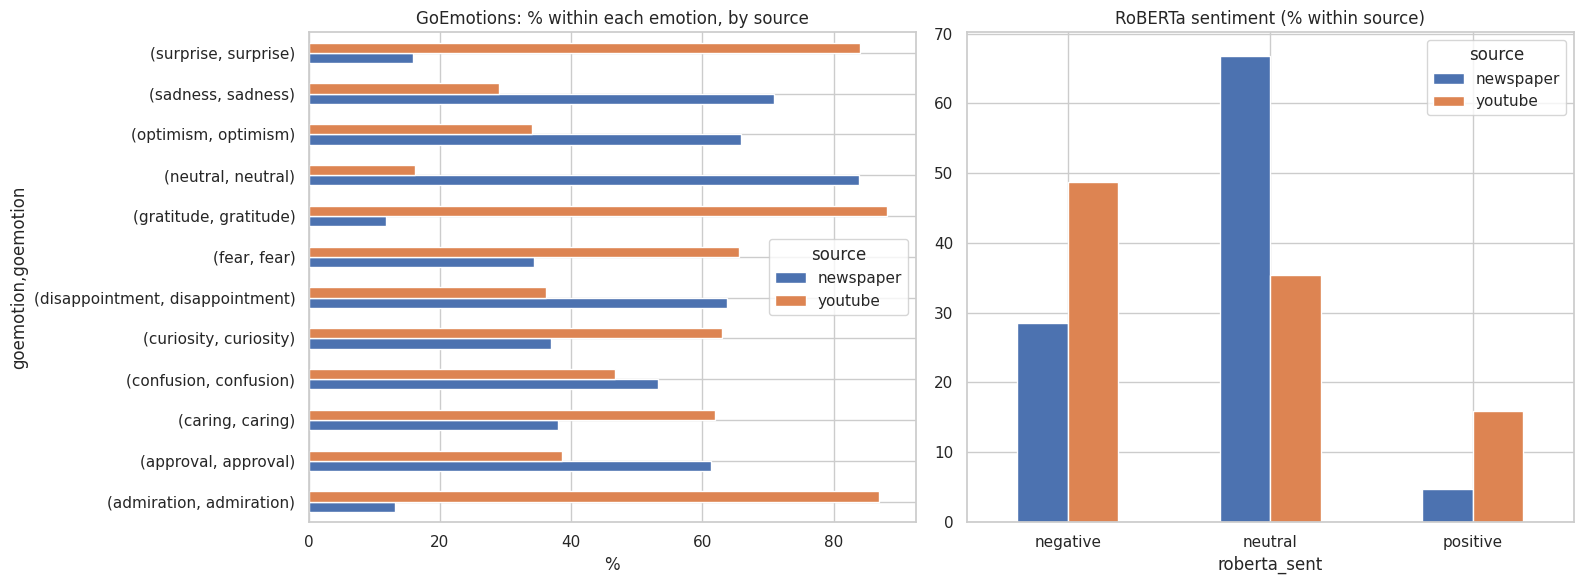

In [7]:
# First, see the distributions side by side
fig,ax=plt.subplots(1,2,figsize=(16,6))
top=sents["goemotion"].value_counts().head(12).index
d=(sents[sents["goemotion"].isin(top)].groupby(["goemotion","source"]).size()
   .groupby(level=0).apply(lambda x:100*x/x.sum()).unstack())
d.plot.barh(ax=ax[0]); ax[0].set_title("GoEmotions: % within each emotion, by source"); ax[0].set_xlabel("%")
(pd.crosstab(sents["roberta_sent"],sents["source"],normalize="columns")*100).plot.bar(ax=ax[1])
ax[1].set_title("RoBERTa sentiment (% within source)"); ax[1].tick_params(axis="x",rotation=0)
plt.tight_layout(); plt.show()

In [8]:
from scipy.spatial.distance import jensenshannon

labels=sorted(sents["goemotion"].unique())
def emo_dist(mask):
    v=sents.loc[mask,"goemotion"].value_counts(normalize=True)
    return np.array([v.get(l,0) for l in labels])

p=emo_dist(sents["source"]=="newspaper")
q=emo_dist(sents["source"]=="youtube")
jsd=jensenshannon(p,q,base=2)

# Bootstrap 95% CI (resample each source with replacement)
rng=np.random.default_rng(0)
news_idx=sents.index[sents["source"]=="newspaper"].to_numpy()
yt_idx  =sents.index[sents["source"]=="youtube"].to_numpy()
boot=[]
for _ in range(500):
    bi=rng.choice(news_idx,len(news_idx),replace=True)
    bj=rng.choice(yt_idx,len(yt_idx),replace=True)
    pp=sents.loc[bi,"goemotion"].value_counts(normalize=True)
    qq=sents.loc[bj,"goemotion"].value_counts(normalize=True)
    pp=np.array([pp.get(l,0) for l in labels]); qq=np.array([qq.get(l,0) for l in labels])
    boot.append(jensenshannon(pp,qq,base=2))
lo,hi=np.percentile(boot,[2.5,97.5])

# Permutation p-value (shuffle labels -> is observed JSD larger than chance?)
alllab=sents["goemotion"].to_numpy(); ns=(sents["source"]=="newspaper").sum()
perm=[]
for _ in range(500):
    sh=rng.permutation(alllab)
    pp=pd.Series(sh[:ns]).value_counts(normalize=True); qq=pd.Series(sh[ns:]).value_counts(normalize=True)
    pp=np.array([pp.get(l,0) for l in labels]); qq=np.array([qq.get(l,0) for l in labels])
    perm.append(jensenshannon(pp,qq,base=2))
pval=(np.sum(np.array(perm)>=jsd)+1)/(len(perm)+1)

print("=== Media–Public Emotional Divergence (GoEmotions) ===")
print(f"JSD = {jsd:.3f}   95% CI [{lo:.3f}, {hi:.3f}]   permutation p = {pval:.4f}")
print("(0 = identical emotion profiles, 1 = maximally different)")

=== Media–Public Emotional Divergence (GoEmotions) ===
JSD = 0.376   95% CI [0.366, 0.388]   permutation p = 0.0020
(0 = identical emotion profiles, 1 = maximally different)


In [9]:
# Same divergence on the other models -> shows the result is robust across instruments
def jsd_between(col):
    labs=sorted(sents[col].unique())
    a=sents[sents.source=="newspaper"][col].value_counts(normalize=True)
    b=sents[sents.source=="youtube"][col].value_counts(normalize=True)
    a=np.array([a.get(l,0) for l in labs]); b=np.array([b.get(l,0) for l in labs])
    return jensenshannon(a,b,base=2)
rows={"GoEmotions":jsd,"RoBERTa sentiment":jsd_between("roberta_sent"),
      "VADER":jsd_between("vader"),"TextBlob":jsd_between("textblob")}
if "valence" in sents.columns:
    g=sents.groupby("source")[["valence","arousal","dominance"]].mean()
    rows["VAD centroid dist"]=float(np.linalg.norm(g.loc["youtube"]-g.loc["newspaper"]))
print("Divergence across instruments (robustness check):")
for k,v in rows.items(): print(f"  {k:20s}: {v:.3f}")

Divergence across instruments (robustness check):
  GoEmotions          : 0.376
  RoBERTa sentiment   : 0.280
  VADER               : 0.071
  TextBlob            : 0.033


## Step 5 — CORE CONTRIBUTION 2: Temporal Divergence Dynamics
How the media–public emotional gap **evolves over time** after the disaster. We compute the
per-day JSD between the two sources' emotion distributions, then look for **change-points**.

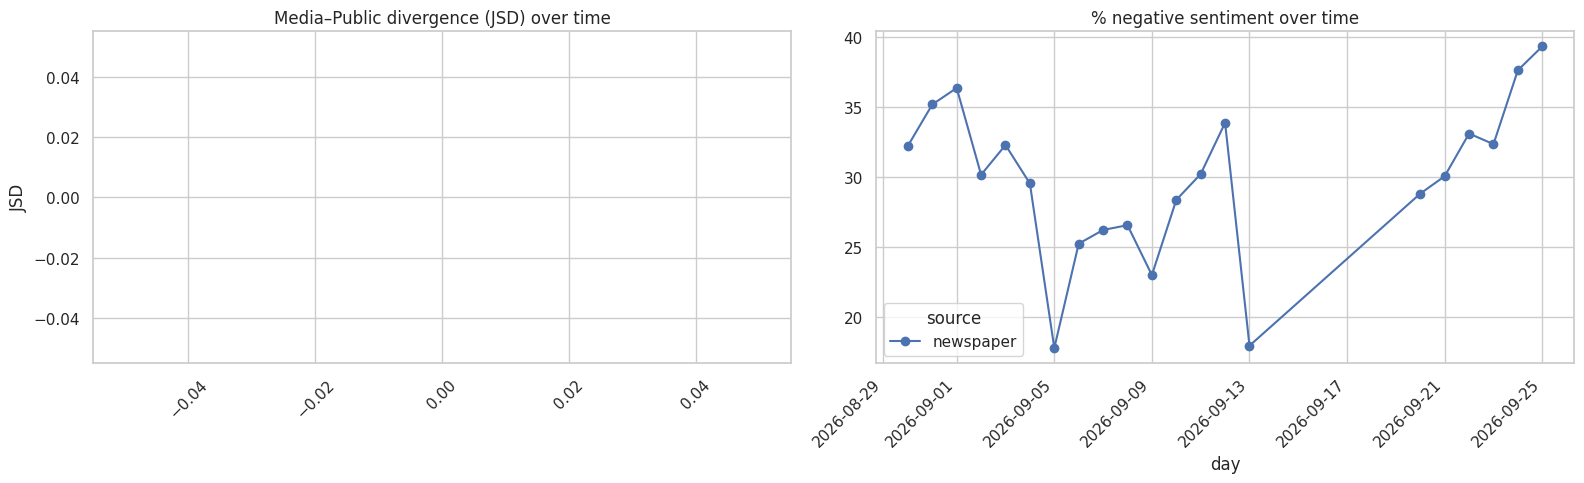

In [10]:
tmp=sents.dropna(subset=["date"]).copy()
tmp["day"]=tmp["date"].dt.floor("D")

# per-day JSD between newspaper and youtube emotion distributions (needs enough of both)
def day_jsd(g):
    a=g[g.source=="newspaper"]["goemotion"]; b=g[g.source=="youtube"]["goemotion"]
    if len(a)<15 or len(b)<15: return np.nan
    av=a.value_counts(normalize=True); bv=b.value_counts(normalize=True)
    av=np.array([av.get(l,0) for l in labels]); bv=np.array([bv.get(l,0) for l in labels])
    return jensenshannon(av,bv,base=2)
series=tmp.groupby("day").apply(day_jsd).dropna()

fig,ax=plt.subplots(1,2,figsize=(16,5))
ax[0].plot(series.index,series.values,marker="o")
ax[0].set_title("Media–Public divergence (JSD) over time"); ax[0].set_ylabel("JSD"); ax[0].tick_params(axis="x",rotation=45)

# % negative over time, each source, + the gap
neg=(tmp.assign(neg=(tmp.roberta_sent=="negative").astype(int))
        .groupby(["day","source"])["neg"].mean().unstack()*100)
neg.plot(ax=ax[1],marker="o"); ax[1].set_title("% negative sentiment over time"); ax[1].tick_params(axis="x",rotation=45)
plt.tight_layout(); plt.show()

In [11]:
# Change-point detection on the divergence series (marks when the gap shifts)
try:
    import ruptures as rpt
    y=series.values.astype(float)
    if len(y)>=6:
        algo=rpt.Pelt(model="rbf").fit(y)
        cps=algo.predict(pen=3)
        print("Change-point day indices:",cps)
        plt.figure(figsize=(12,4))
        plt.plot(series.index,y,marker="o")
        for c in cps[:-1]:
            plt.axvline(series.index[min(c,len(series)-1)],color="red",ls="--")
        plt.title("Divergence with detected change-points"); plt.ylabel("JSD")
        plt.xticks(rotation=45); plt.tight_layout(); plt.show()
    else:
        print("Not enough days for change-point detection.")
except Exception as e:
    print("Change-point step skipped:",e)

Not enough days for change-point detection.


## Step 6 — Supporting rigor: XAI (which words drive the divergence)
Measles-consistent XAI: **TF-IDF + XGBoost + SHAP/LIME**. Here the classifier predicts the
**source** (media vs public), so the explanations reveal *which words separate media language from public language* —
directly interpreting the divergence.

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import xgboost as xgb

X=sents["text"].astype(str).values
y=(sents["source"]=="youtube").astype(int).values   # 1=public(youtube), 0=media(newspaper)
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.25,random_state=0,stratify=y)

vec=TfidfVectorizer(min_df=3,ngram_range=(1,2),stop_words="english",max_features=20000)
Xtr_v=vec.fit_transform(Xtr); Xte_v=vec.transform(Xte)
clf=xgb.XGBClassifier(n_estimators=300,max_depth=6,learning_rate=0.2,
                      subsample=0.9,eval_metric="logloss",n_jobs=4)
clf.fit(Xtr_v,ytr)
print(classification_report(yte,clf.predict(Xte_v),target_names=["media","public"]))

              precision    recall  f1-score   support

       media       0.94      0.95      0.94      4810
      public       0.85      0.80      0.83      1602

    accuracy                           0.92      6412
   macro avg       0.89      0.88      0.89      6412
weighted avg       0.92      0.92      0.92      6412



In [13]:
# Global word importance (SHAP) — which words push toward "public" vs "media"
import shap
names=np.array(vec.get_feature_names_out())
expl=shap.TreeExplainer(clf)
samp=Xte_v[:800]
sv=expl.shap_values(samp)
mean_shap=sv.mean(axis=0)                      # signed mean: +ve -> public, -ve -> media
order=np.argsort(mean_shap)
print("Top words pushing toward PUBLIC (youtube):")
print("  ", ", ".join(names[order[-15:]][::-1]))
print("\nTop words pushing toward MEDIA (newspaper):")
print("  ", ", ".join(names[order[:15]]))

Top words pushing toward PUBLIC (youtube):
   items, flash floods, risks, thank, video, stuck, family, peace, rapidly, chance, terrifying, brought, year, threat, responsibility

Top words pushing toward MEDIA (newspaper):
   said, rescue, hydropower, disaster, floods, relief, tunnel, authorities, bodies, search, minister, foreign, rescued, rescuers, trishuli


In [14]:
# LIME on two example sentences (local explanation), measles-consistent
from lime.lime_text import LimeTextExplainer
from sklearn.pipeline import make_pipeline
pipe=make_pipeline(vec,clf)
ex=LimeTextExplainer(class_names=["media","public"])
for s in sents.groupby("source").apply(lambda d:d.sample(1,random_state=2))["text"].tolist():
    e=ex.explain_instance(s,pipe.predict_proba,num_features=8)
    print("\nTEXT:",s[:120])
    for w,wt in e.as_list():
        print(f"   {w:22s} -> {'public' if wt>0 else 'media':7s} ({wt:+.3f})")


TEXT: Twelve days on, very little is known about the victims in Tibet as Chinese authorities have restricted reporting on the 
   authorities            -> media   (-0.275)
   restricted             -> media   (-0.133)
   victims                -> media   (-0.128)
   known                  -> media   (-0.125)
   days                   -> media   (-0.120)
   little                 -> media   (-0.117)
   reporting              -> media   (-0.085)
   Chinese                -> public  (+0.072)

TEXT: The mountain roads along those rivers are usually backed up with traffic and tourists buses.
   mountain               -> public  (+0.237)
   roads                  -> media   (-0.036)
   tourists               -> public  (+0.029)
   traffic                -> public  (+0.024)
   buses                  -> public  (+0.013)
   usually                -> public  (+0.012)
   rivers                 -> public  (+0.007)
   backed                 -> public  (+0.004)


## Step 7 — Save results

In [15]:
sents.to_csv("nepal_divergence_results.csv",index=False,encoding="utf-8-sig")
summary={"JSD_goemotions":float(jsd),"JSD_CI":[float(lo),float(hi)],"perm_p":float(pval),
         "divergence_by_model":{k:float(v) for k,v in rows.items()}}
open("divergence_summary.json","w").write(json.dumps(summary,indent=2))
from google.colab import files
files.download("nepal_divergence_results.csv")
files.download("divergence_summary.json")
print("Saved. Core number — JSD:",round(jsd,3),"CI",[round(lo,3),round(hi,3)],"p",round(pval,4))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved. Core number — JSD: 0.376 CI [np.float64(0.366), np.float64(0.388)] p 0.002


dated: {'newspaper': 19239, 'youtube': 6407}
Weekly JSD:
 week
2026-08-24    0.428
2026-08-31    0.361
2026-09-07    0.398
2026-09-14    0.435
2026-09-21    0.470
dtype: float64


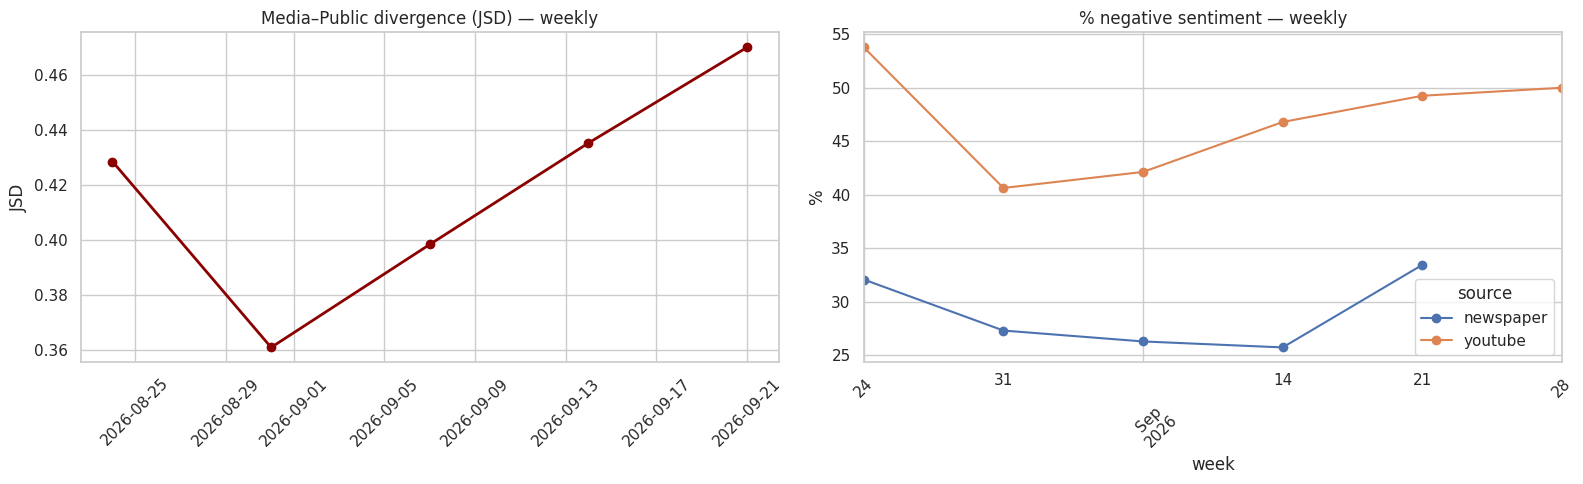

In [16]:
# ---- Temporal divergence (FINAL — handles the two different date formats) ----
import pandas as pd, numpy as np, re
from scipy.spatial.distance import jensenshannon

# মূল ফাইল থেকে তারিখ আবার নেওয়া (Step 1 এ হারিয়েছিল)
news_raw = pd.read_csv(NEWS_CSV); yt_raw = pd.read_csv(YT_CSV)
def _clean(t):
    t=re.sub(r"http\S+"," ",str(t)); t=re.sub(r"<[^>]+>"," ",t); return re.sub(r"\s+"," ",t).strip()
def _map(df,tcol,dcol):
    m={}
    for _,r in df.iterrows():
        for s in re.split(r"(?<=[.!?])\s+", _clean(r[tcol])):
            if len(s.split())>=5: m.setdefault(str(s.strip()), str(r[dcol]))
    return m
news_map=_map(news_raw,NEWS_TEXT,NEWS_DATE); yt_map=_map(yt_raw,YT_TEXT,YT_DATE)

sents=sents.reset_index(drop=True)
sents["source"]=sents["source"].astype(str); sents["text"]=sents["text"].astype(str)
dates=[(news_map if str(sents["source"].iloc[i])=="newspaper" else yt_map).get(str(sents["text"].iloc[i]))
       for i in range(len(sents))]
# ★ আসল fix: format="mixed" — newspaper আর youtube এর তারিখ format আলাদা
sents["date"]=pd.to_datetime(pd.Series(dates,index=sents.index),errors="coerce",utc=True,format="mixed")
print("dated:", sents.groupby("source")["date"].apply(lambda x:x.notna().sum()).to_dict())

sents["week"]=sents["date"].dt.tz_convert(None).dt.to_period("W").dt.start_time
def _bin(g):
    a=g[g.source=="newspaper"]["goemotion"]; b=g[g.source=="youtube"]["goemotion"]
    if len(a)<10 or len(b)<10: return np.nan
    av=a.value_counts(normalize=True); bv=b.value_counts(normalize=True)
    av=np.array([av.get(l,0) for l in labels]); bv=np.array([bv.get(l,0) for l in labels])
    return jensenshannon(av,bv,base=2)
series=sents.groupby("week").apply(_bin).dropna()
print("Weekly JSD:\n", series.round(3))

fig,ax=plt.subplots(1,2,figsize=(16,5))
ax[0].plot(series.index,series.values,marker="o",lw=2,color="darkred")
ax[0].set_title("Media–Public divergence (JSD) — weekly"); ax[0].set_ylabel("JSD"); ax[0].tick_params(axis="x",rotation=45)
neg=(sents.dropna(subset=["date"]).assign(neg=lambda d:(d["roberta_sent"]=="negative").astype(int))
        .groupby(["week","source"])["neg"].mean().unstack()*100)
neg.plot(ax=ax[1],marker="o"); ax[1].set_title("% negative sentiment — weekly"); ax[1].set_ylabel("%"); ax[1].tick_params(axis="x",rotation=45)
plt.tight_layout(); plt.show()

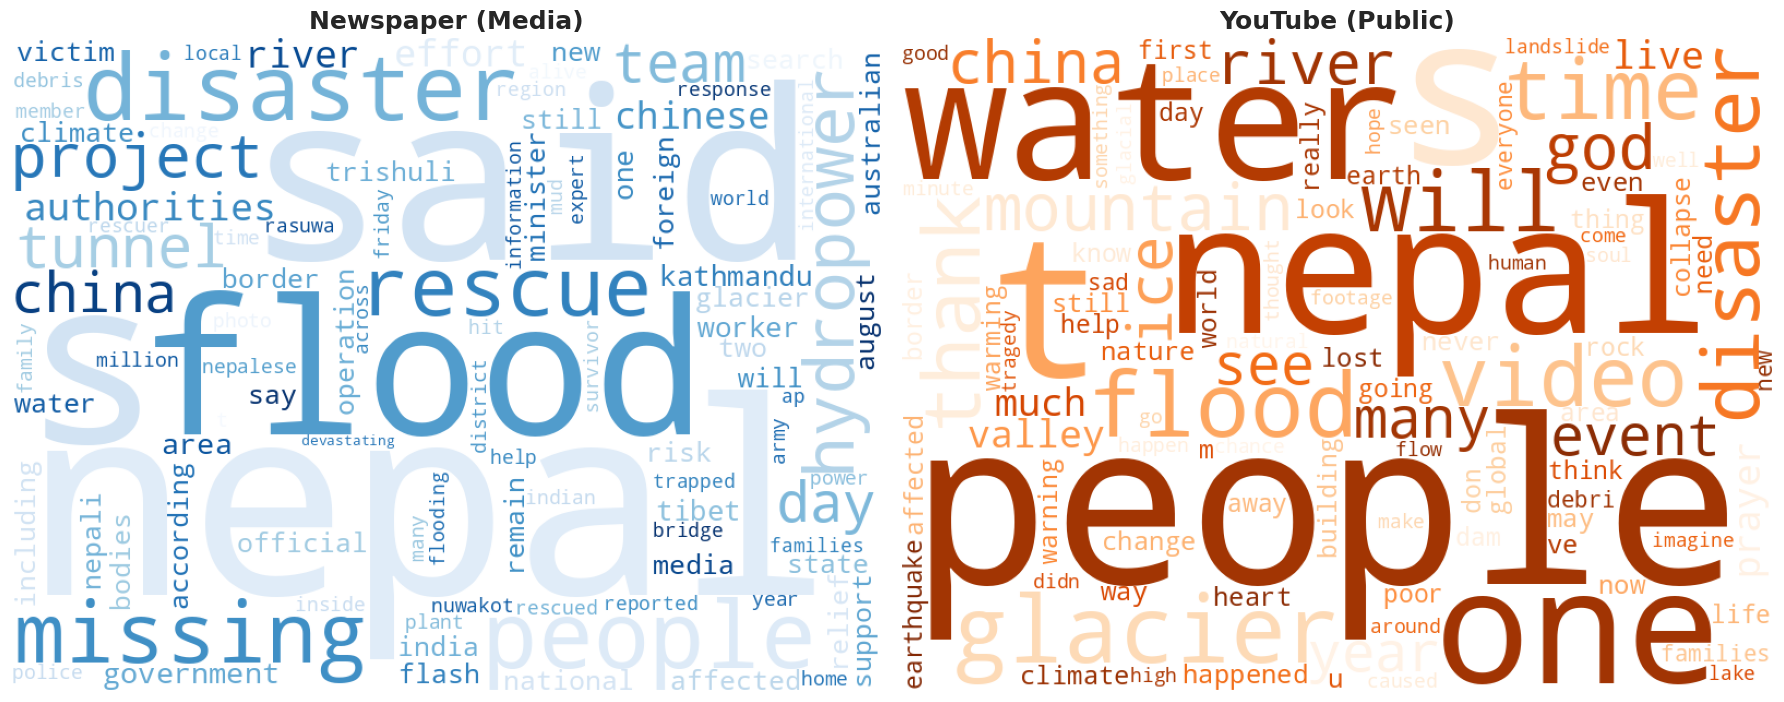

In [17]:
!pip install wordcloud -q
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt, re

stop=set(STOPWORDS)   # শুধু সাধারণ stopword, custom বাদ নেই

def corpus(src):
    return re.sub(r'[^a-z\s]',' ',' '.join(sents[sents.source==src]['text'].astype(str)).lower())

fig,ax=plt.subplots(1,2,figsize=(18,8))
for i,(src,cmap,title) in enumerate([('newspaper','Blues','Newspaper (Media)'),
                                      ('youtube','Oranges','YouTube (Public)')]):
    wc=WordCloud(width=800,height=600,background_color='white',colormap=cmap,
                 stopwords=stop,max_words=100,collocations=False).generate(corpus(src))
    ax[i].imshow(wc); ax[i].axis('off'); ax[i].set_title(title,fontsize=18,fontweight='bold')
plt.tight_layout(); plt.show()

In [18]:
# ---- Recent (2025) model: ModernBERT GoEmotions ----
from transformers import pipeline

# ModernBERT large — 2025, GoEmotions 28 labels (তোমার আগের GoEmotions এর নতুন প্রজন্ম)
modernbert = pipeline("text-classification",
    model="cirimus/modernbert-large-go-emotions",
    device=DEVICE, truncation=True, max_length=128, top_k=1)

texts = sents["text"].astype(str).tolist()
mb = modernbert(texts, batch_size=16, truncation=True, max_length=128)
sents["modernbert_emotion"] = [x[0]["label"] if isinstance(x, list) else x["label"] for x in mb]

print("ModernBERT emotion done.")

# দুটো GoEmotions model কতটা একমত? (validation — reviewer পছন্দ করবে)
agree = (sents["goemotion"] == sents["modernbert_emotion"]).mean()
print(f"\nপুরনো (RoBERTa) vs নতUন (ModernBERT) GoEmotions agreement: {agree:.1%}")

# দুই model এ media vs public divergence তুলনা
from scipy.spatial.distance import jensenshannon
import numpy as np
def jsd_for(col):
    labs = sorted(sents[col].unique())
    a = sents[sents.source=="newspaper"][col].value_counts(normalize=True)
    b = sents[sents.source=="youtube"][col].value_counts(normalize=True)
    a = np.array([a.get(l,0) for l in labs]); b = np.array([b.get(l,0) for l in labs])
    return jensenshannon(a, b, base=2)
print(f"\nDivergence (RoBERTa GoEmotions):    {jsd_for('goemotion'):.3f}")
print(f"Divergence (ModernBERT GoEmotions): {jsd_for('modernbert_emotion'):.3f}")

config.json:   0%|          | 0.00/2.56k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.58GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/174 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.58M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

ModernBERT emotion done.

পুরনো (RoBERTa) vs নতUন (ModernBERT) GoEmotions agreement: 87.2%

Divergence (RoBERTa GoEmotions):    0.376
Divergence (ModernBERT GoEmotions): 0.419


In [19]:
!pip install xgboost scikit-learn imbalanced-learn -q

In [20]:
import pandas as pd, numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score
import xgboost as xgb

# sents এ তোমার vader label আছে (positive/negative/neutral) — এটাই target
df = sents.dropna(subset=['vader']).copy()
df['text'] = df['text'].astype(str)

# label encode
lab_map = {'negative':0,'neutral':1,'positive':2}
df['y'] = df['vader'].map(lab_map)

X = df['text'].values; y = df['y'].values
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

vec = TfidfVectorizer(min_df=3, ngram_range=(1,2), stop_words='english', max_features=20000)
Xtr_v = vec.fit_transform(Xtr); Xte_v = vec.transform(Xte)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Linear SVM': LinearSVC(class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=200, n_jobs=4, class_weight='balanced'),
    'XGBoost': xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.2,
                                 subsample=0.9, eval_metric='mlogloss', n_jobs=4)
}

results = {}
for name, m in models.items():
    m.fit(Xtr_v, ytr)
    pred = m.predict(Xte_v)
    acc = accuracy_score(yte, pred)
    f1 = f1_score(yte, pred, average='macro')
    results[name] = {'accuracy':acc, 'macro_f1':f1}
    print(f"{name}: accuracy={acc:.3f}, macro-F1={f1:.3f}")

print("\n=== Best model detailed report ===")
best = max(results, key=lambda k: results[k]['macro_f1'])
print("Best:", best)
bm = models[best]; pred = bm.predict(Xte_v)
print(classification_report(yte, pred, target_names=['negative','neutral','positive']))

# ফল সেভ (report এর জন্য আমাকে এই সংখ্যাগুলো দিও)
pd.DataFrame(results).T.to_csv('ml_results.csv')
print("\nসব model এর ফল:")
print(pd.DataFrame(results).T.round(3).to_string())

Logistic Regression: accuracy=0.863, macro-F1=0.860
Linear SVM: accuracy=0.877, macro-F1=0.874
Random Forest: accuracy=0.877, macro-F1=0.874
XGBoost: accuracy=0.872, macro-F1=0.869

=== Best model detailed report ===
Best: Random Forest
              precision    recall  f1-score   support

    negative       0.91      0.89      0.90      2703
     neutral       0.81      0.91      0.86      1702
    positive       0.91      0.83      0.87      2007

    accuracy                           0.88      6412
   macro avg       0.87      0.88      0.87      6412
weighted avg       0.88      0.88      0.88      6412


সব model এর ফল:
                     accuracy  macro_f1
Logistic Regression     0.863     0.860
Linear SVM              0.877     0.874
Random Forest           0.877     0.874
XGBoost                 0.872     0.869


In [21]:
!pip install gensim pyLDAvis -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 39.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 65.6 MB/s eta 0:00:00


In [22]:
import gensim
from gensim import corpora
from gensim.models import LdaModel
import re
from nltk.corpus import stopwords
import nltk; nltk.download('stopwords', quiet=True)

stop = set(stopwords.words('english'))
stop.update(['nepal','flood','floods','said','will','one','also','people','year','time'])

def preprocess(texts):
    out=[]
    for t in texts:
        words = re.findall(r'[a-z]+', str(t).lower())
        words = [w for w in words if w not in stop and len(w)>3]
        if len(words)>=3: out.append(words)
    return out

def run_lda(texts, source, n_topics=5):
    docs = preprocess(texts)
    dic = corpora.Dictionary(docs)
    dic.filter_extremes(no_below=5, no_above=0.5)
    corp = [dic.doc2bow(d) for d in docs]
    lda = LdaModel(corp, num_topics=n_topics, id2word=dic, passes=8, random_state=42)
    print(f"\n===== {source} TOPICS =====")
    for i, topic in lda.print_topics(num_words=8):
        words = re.findall(r'"([^"]+)"', topic)
        print(f"Topic {i+1}: {', '.join(words)}")
    return lda

print("Topic modeling চলছে (একটু সময় নেবে)...")
lda_news = run_lda(sents[sents.source=='newspaper']['text'].tolist(), 'NEWSPAPER (Media)')
lda_yt   = run_lda(sents[sents.source=='youtube']['text'].tolist(), 'YOUTUBE (Public)')

Topic modeling চলছে (একটু সময় নেবে)...

===== NEWSPAPER (Media) TOPICS =====
Topic 1: world, warning, risk, international, assessment, area, china, could
Topic 2: rescue, hydropower, efforts, projects, support, search, india, united
Topic 3: missing, disaster, still, glacier, prime, minister, august, shah
Topic 4: river, plants, development, away, water, family, hydropower, china
Topic 5: climate, change, years, trishuli, world, disaster, chinese, global

===== YOUTUBE (Public) TOPICS =====
Topic 1: nature, many, years, best, always, seen, happen, climate
Topic 2: like, lost, disaster, prayers, affected, everyone, heart, families
Topic 3: water, glacier, river, mountain, valley, border, rock, debris
Topic 4: video, thank, climate, change, well, much, thanks, human
Topic 5: would, china, happened, could, even, landslide, much, global
